# Disaster Type Classifier: Training Notebook

Fine-tunes a pretrained model (default: MobileNetV3, CPU-friendly) on the CrisisNLP **Disaster types** dataset (7 classes: earthquake, fire, flood, hurricane, landslide, other_disaster, not_disaster).

**How to use:** edit the paths and settings in section 2, then run the cells from top to bottom.
Training outputs (`best_model.pt`, `classes.json`, `confusion_matrix.png`) are saved to `outputs/`.

**Note:** `check_model.ipynb` imports `train_disaster_types.py`, so keep that file too.

In [34]:
from google.colab import drive

drive.mount('/content/drive')

# Extract to Colab's local disk (much faster to read than Drive)
!mkdir -p /content/data
!tar -xzf /content/drive/MyDrive/disaster/data_disaster_types.tar.gz -C /content/data
!find /content/data -maxdepth 2 | head -20

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/data
/content/data/data_disaster_types
/content/data/data_disaster_types/consolidated_disaster_types_test_final.tsv
/content/data/data_disaster_types/consolidated_disaster_types_train_final.tsv
/content/data/data_disaster_types/data
/content/data/data_disaster_types/consolidated_disaster_types_dev_final.tsv


## 1. Install and import

In [35]:
!pip install timm -q

In [36]:
import csv
import json
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import timm
import torch
from PIL import Image, ImageFile
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True  # tolerate slightly truncated JPEGs

## 2. Config
Change `ROOT` to the folder that contains the `data` folder and the three `.tsv` files.
On a GPU (Kaggle/Colab) use: `convnext_tiny`, `IMG_SIZE = 224`, `EPOCHS = 12`, `UNFREEZE_LAST_FRACTION = 1`.

In [37]:
# ----------------------------- CONFIG (Colab / GPU) -------------------------
ROOT = Path("/content/data/data_disaster_types")   # folder containing data/ and the .tsv files

TRAIN_TSV = ROOT / "consolidated_disaster_types_train_final.tsv"
DEV_TSV = ROOT / "consolidated_disaster_types_dev_final.tsv"
TEST_TSV = ROOT / "consolidated_disaster_types_test_final.tsv"

MODEL_NAME = "convnext_tiny"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 12
LR_BACKBONE = 1e-4
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
NUM_WORKERS = 2
UNFREEZE_LAST_FRACTION = 1     # 1 = full fine-tuning (fine on GPU)
PATIENCE = 4
SEED = 42
OUT_DIR = Path("/content/drive/MyDrive/disaster/outputs")
# ----------------------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

## 3. Helper functions and model

In [38]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [39]:
def load_split(tsv_path, name):
    """Read a TSV split, drop rows whose image file is missing."""
    df = pd.read_csv(tsv_path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
    df = df[["image_path", "class_label"]].dropna()
    df["class_label"] = df["class_label"].str.strip()
    df["full_path"] = df["image_path"].apply(lambda p: str(ROOT / p.strip().replace("data/aidr_disaster_types/", "data/", 1)))
    exists = df["full_path"].apply(os.path.exists)
    n_missing = int((~exists).sum())
    if n_missing:
        print(f"[{name}] dropping {n_missing} rows with missing image files")
    df = df[exists].reset_index(drop=True)
    print(f"[{name}] {len(df)} images")
    return df

In [ ]:
class DisasterDataset(Dataset):
    def __init__(self, df, class_to_idx, transform):
        self.paths = df["full_path"].tolist()
        self.labels = [class_to_idx[c] for c in df["class_label"]]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert("RGB")
        except (OSError, ValueError):
            img = Image.new("RGB", (IMG_SIZE, IMG_SIZE), (128, 128, 128))
        return self.transform(img), self.labels[idx]

In [41]:
class DisasterClassifier(nn.Module):
    """Backbone + head, so a drone head can be added later."""

    def __init__(self, model_name, num_classes):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=True, num_classes=0)
        self.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(self.backbone.num_features, num_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))

In [42]:
def build_transforms():
    mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3),
        transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize(int(IMG_SIZE * 1.14)),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    return train_tf, eval_tf

In [43]:
@torch.no_grad()
def evaluate(model, loader, device, criterion=None):
    model.eval()
    all_preds, all_labels, total_loss = [], [], 0.0
    for imgs, labels in tqdm(loader, leave=False, desc="eval"):
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            logits = model(imgs)
            if criterion is not None:
                total_loss += criterion(logits, labels).item() * imgs.size(0)
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    acc = float(np.mean(np.array(all_preds) == np.array(all_labels)))
    return total_loss / len(loader.dataset), acc, macro_f1, all_labels, all_preds

In [44]:
def save_confusion_matrix(labels, preds, classes, path):
    import matplotlib.pyplot as plt

    cm = confusion_matrix(labels, preds, normalize="true")
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticklabels(classes)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    fig.colorbar(im)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)  # saved to file; displayed later

In [45]:
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [48]:
def fixed_path(p):
    return str(ROOT / p.strip().replace("data/aidr_disaster_types/", "data/", 1))

raw = pd.read_csv(TRAIN_TSV, sep="\t", quoting=csv.QUOTE_NONE, dtype=str)
raw["exists"] = raw["image_path"].apply(lambda p: os.path.exists(fixed_path(p)))
print("train rows found:", raw["exists"].sum(), "of", len(raw))
print(raw.groupby("class_label")["exists"].agg(found="sum", total="count"))
print("\nexample path:", fixed_path(raw["image_path"].iloc[0]))

train rows found: 12846 of 12846
                found  total
class_label                 
earthquake       2058   2058
fire             1270   1270
flood            2336   2336
hurricane        1444   1444
landslide         940    940
not_disaster     3666   3666
other_disaster   1132   1132

example path: /content/data/data_disaster_types/data/harvey/4_9_2017/904844672551542790_3.jpg


## 4. Load data

In [ ]:
train_df = load_split(TRAIN_TSV, "train")
dev_df = load_split(DEV_TSV, "dev")
test_df = load_split(TEST_TSV, "test")

classes = sorted(train_df["class_label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
print("Classes:", class_to_idx)
print("\nTrain class counts:\n", train_df["class_label"].value_counts(), "\n")

# any label in dev/test that's not in train would crash later; catch it now
for name, df in (("dev", dev_df), ("test", test_df)):
    unknown = set(df["class_label"]) - set(classes)
    assert not unknown, f"{name} has unknown labels: {unknown}"

with open(OUT_DIR / "classes.json", "w") as f:
    json.dump(classes, f)

train_tf, eval_tf = build_transforms()
train_ds = DisasterDataset(train_df, class_to_idx, train_tf)
dev_ds = DisasterDataset(dev_df, class_to_idx, eval_tf)
test_ds = DisasterDataset(test_df, class_to_idx, eval_tf)

kw = {
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0,
}
train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True, drop_last=True, **kw)
dev_loader = DataLoader(dev_ds, BATCH_SIZE * 2, shuffle=False, **kw)
test_loader = DataLoader(test_ds, BATCH_SIZE * 2, shuffle=False, **kw)

[train] 12846 images
[dev] 1470 images
[test] 3195 images
Classes: {'earthquake': 0, 'fire': 1, 'flood': 2, 'hurricane': 3, 'landslide': 4, 'not_disaster': 5, 'other_disaster': 6}

Train class counts:
 class_label
not_disaster      3666
flood             2336
earthquake        2058
hurricane         1444
fire              1270
other_disaster    1132
landslide          940
Name: count, dtype: int64 



## 5. Class weights (handles imbalance)

In [50]:
counts = train_df["class_label"].value_counts().reindex(classes).values.astype(float)
weights = counts.sum() / (len(classes) * counts)
weights = torch.tensor(weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.1)
eval_criterion = nn.CrossEntropyLoss()

## 6. Model and optimizer

In [51]:
torch.set_num_threads(os.cpu_count() or 4)
model = DisasterClassifier(MODEL_NAME, len(classes)).to(device)

# freeze the early part of the backbone (big speedup on CPU)
bb_params = list(model.backbone.parameters())
n_trainable = int(len(bb_params) * UNFREEZE_LAST_FRACTION)
for i, prm in enumerate(bb_params):
    prm.requires_grad = i >= len(bb_params) - n_trainable
print(f"Backbone tensors trainable: {n_trainable}/{len(bb_params)}")

param_groups = [{"params": model.head.parameters(), "lr": LR_HEAD}]
if n_trainable:
    param_groups.append({"params": [q for q in bb_params if q.requires_grad], "lr": LR_BACKBONE})
optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Backbone tensors trainable: 180/180


/tmp/ipykernel_2188/3294281435.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")


## 7. Train
This is the slow part. Watch the first epoch time to estimate the total. The best model (by dev macro-F1) is saved automatically.

In [52]:
best_f1, bad_epochs = 0.0, 0
ckpt_path = OUT_DIR / "best_model.pt"

for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for imgs, labels in tqdm(train_loader, desc=f"epoch {epoch}/{EPOCHS}"):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            loss = criterion(model(imgs), labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * imgs.size(0)
    scheduler.step()

    train_loss = running / (len(train_loader) * BATCH_SIZE)
    dev_loss, dev_acc, dev_f1, _, _ = evaluate(model, dev_loader, device, eval_criterion)
    print(f"epoch {epoch}: train_loss={train_loss:.4f} dev_loss={dev_loss:.4f} "
          f"dev_acc={dev_acc:.4f} dev_macro_f1={dev_f1:.4f}")

    if dev_f1 > best_f1:
        best_f1, bad_epochs = dev_f1, 0
        torch.save({"model": model.state_dict(), "classes": classes,
                    "model_name": MODEL_NAME, "img_size": IMG_SIZE}, ckpt_path)
        print(f"  saved best model (dev macro-F1 {best_f1:.4f})")
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping.")
            break

epoch 1/12:   0%|          | 0/401 [00:00<?, ?it/s]

eval:   0%|          | 0/23 [00:00<?, ?it/s]

epoch 1: train_loss=1.2090 dev_loss=0.7461 dev_acc=0.7735 dev_macro_f1=0.7305
  saved best model (dev macro-F1 0.7305)


epoch 2/12:   0%|          | 0/401 [00:00<?, ?it/s]

eval:   0%|          | 0/23 [00:00<?, ?it/s]

...

eval:   0%|          | 0/23 [00:00<?, ?it/s]

epoch 11: train_loss=0.5391 dev_loss=0.6710 dev_acc=0.8136 dev_macro_f1=0.7881


epoch 12/12:   0%|          | 0/401 [00:00<?, ?it/s]

eval:   0%|          | 0/23 [00:00<?, ?it/s]

epoch 12: train_loss=0.5359 dev_loss=0.6746 dev_acc=0.8122 dev_macro_f1=0.7871


## 8. Final test evaluation (run once)

In [53]:
print("\nLoading best model for final TEST evaluation...")
state = torch.load(ckpt_path, map_location=device)
model.load_state_dict(state["model"])
_, test_acc, test_f1, y_true, y_pred = evaluate(model, test_loader, device)
print(f"\nTEST accuracy: {test_acc:.4f} | macro-F1: {test_f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=3))
save_confusion_matrix(y_true, y_pred, classes, OUT_DIR / "confusion_matrix.png")
print(f"Saved: {ckpt_path}, classes.json, confusion_matrix.png in {OUT_DIR.resolve()}")


Loading best model for final TEST evaluation...


eval:   0%|          | 0/50 [00:00<?, ?it/s]


TEST accuracy: 0.8394 | macro-F1: 0.8156

                precision    recall  f1-score   support

    earthquake      0.836     0.871     0.853       404
          fire      0.899     0.925     0.912       280
         flood      0.870     0.880     0.875       599
     hurricane      0.742     0.696     0.718       352
     landslide      0.853     0.869     0.861       268
  not_disaster      0.888     0.907     0.898       990
other_disaster      0.632     0.556     0.592       302

      accuracy                          0.839      3195
     macro avg      0.817     0.815     0.816      3195
  weighted avg      0.836     0.839     0.837      3195

Saved: /content/drive/MyDrive/disaster/outputs/best_model.pt, classes.json, confusion_matrix.png in /content/drive/MyDrive/disaster/outputs


### Confusion matrix

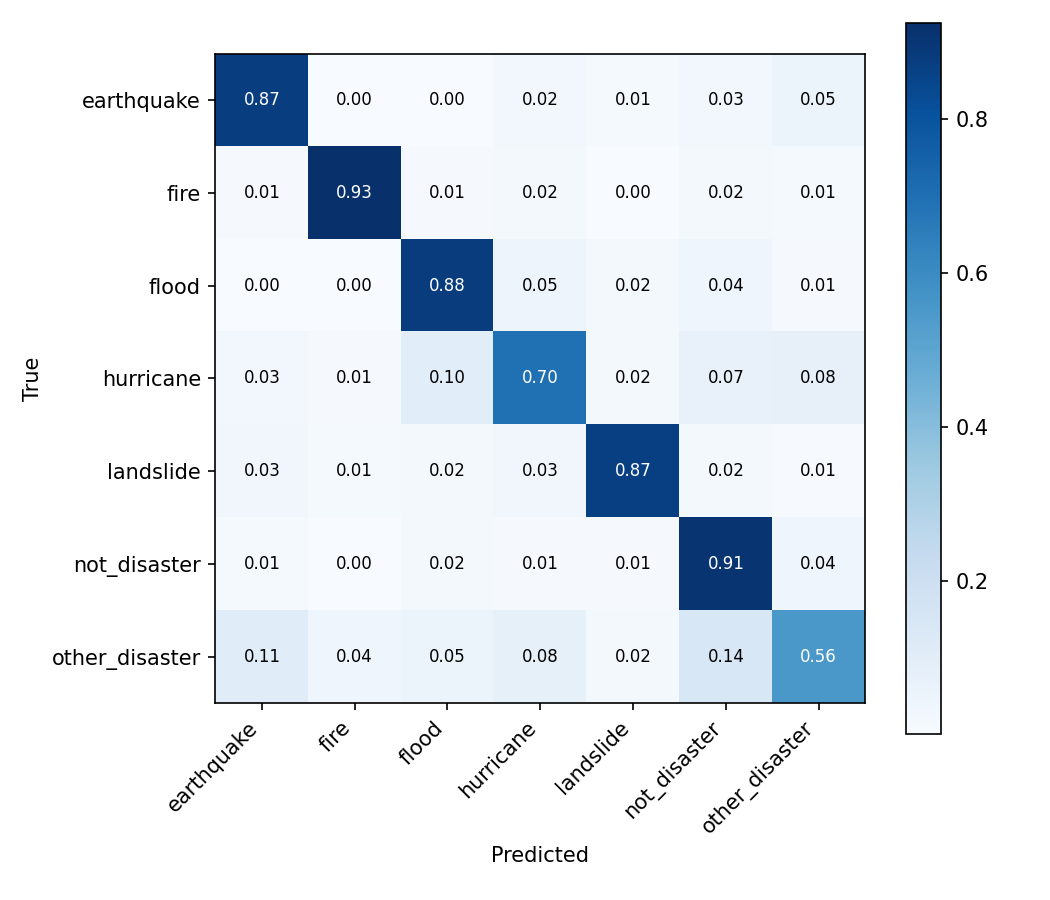

In [54]:
from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(filename=str(OUT_DIR / "confusion_matrix.png")))

## 9. Predict a single image
This is the function you will reuse in the FastAPI backend.

In [55]:
@torch.no_grad()
def predict_image(image_path, ckpt_path=OUT_DIR / "best_model.pt", review_threshold=0.6):
    """Use this inside your FastAPI endpoint. Returns top-3 + needs_review flag."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    state = torch.load(ckpt_path, map_location=device)
    classes = state["classes"]
    model = DisasterClassifier(state["model_name"], len(classes)).to(device)
    model.load_state_dict(state["model"])
    model.eval()

    _, eval_tf = build_transforms()
    img = eval_tf(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
    probs = torch.softmax(model(img), dim=1)[0]
    top_p, top_i = probs.topk(min(3, len(classes)))
    top3 = [{"label": classes[i], "confidence": round(p.item(), 4)}
            for p, i in zip(top_p, top_i)]
    return {
        "prediction": top3[0]["label"],
        "confidence": top3[0]["confidence"],
        "top3": top3,
        "needs_review": top3[0]["confidence"] < review_threshold,
    }

In [ ]:
# result = predict_image(r"C:\path\to\image.jpg")
# print(result)

## Next steps
- Open `check_model.ipynb` for a full review (confusion matrix, confident mistakes, Grad-CAM, confidence thresholds).
- Wrap `predict_image` in a FastAPI endpoint (load the model once at startup).